In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Importing Dataset

In [ ]:
file_path = '/content/drive/MyDrive/Hypertension_dataset.xlsx'

import pandas as pd
df = pd.read_excel(file_path)
df.head()

,Age,Sex,Education,Occupation,Monthly Income,Residence,Systolic BP,Diastolic BP,Elevated Creatinine,Diabetes Mellitus,...,Elevated Cholesterol,Smoking,LVH,IHD,CVD,Retinopathy,Treatment,Control Status,Physical Activity,Dietary Habits
0,71,Female,Primary,Service,>15000,Rural,135,90,No,No,...,No,No,No,No,No,No,Combination Drugs,Controlled,Yes,Unhealthy
1,46,Female,Primary,Business,<5000,Urban,129,92,No,No,...,No,No,No,No,No,No,Combination Drugs,Uncontrolled,Yes,Unhealthy
2,48,Female,Secondary,Housewife,<5000,Rural,139,81,No,No,...,No,No,No,No,Yes,No,Combination Drugs,Controlled,Yes,Healthy
3,41,Male,Secondary,Housewife,5001-10000,Sub-urban,123,79,No,No,...,No,No,No,No,Yes,No,Combination Drugs,Uncontrolled,Yes,Unhealthy
4,55,Male,Primary,Business,5001-10000,Sub-urban,136,105,Yes,No,...,No,No,No,No,No,No,Combination Drugs,Controlled,Yes,Unhealthy


In [ ]:
df

,Age,Sex,Education,Occupation,Monthly Income,Residence,Systolic BP,Diastolic BP,Elevated Creatinine,Diabetes Mellitus,...,Elevated Cholesterol,Smoking,LVH,IHD,CVD,Retinopathy,Treatment,Control Status,Physical Activity,Dietary Habits
0,71,Female,Primary,Service,>15000,Rural,135,90,No,No,...,No,No,No,No,No,No,Combination Drugs,Controlled,Yes,Unhealthy
1,46,Female,Primary,Business,<5000,Urban,129,92,No,No,...,No,No,No,No,No,No,Combination Drugs,Uncontrolled,Yes,Unhealthy
2,48,Female,Secondary,Housewife,<5000,Rural,139,81,No,No,...,No,No,No,No,Yes,No,Combination Drugs,Controlled,Yes,Healthy
3,41,Male,Secondary,Housewife,5001-10000,Sub-urban,123,79,No,No,...,No,No,No,No,Yes,No,Combination Drugs,Uncontrolled,Yes,Unhealthy
4,55,Male,Primary,Business,5001-10000,Sub-urban,136,105,Yes,No,...,No,No,No,No,No,No,Combination Drugs,Controlled,Yes,Unhealthy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,46,Female,No education,Unemployed,<5000,Urban,135,76,No,No,...,No,Yes,No,No,No,No,Combination Drugs,Controlled,No,Healthy
99996,36,Female,Higher Secondary,Service,<5000,Urban,136,85,Yes,No,...,No,No,No,No,No,No,Combination Drugs,Uncontrolled,No,Healthy
99997,77,Male,Secondary,Housewife,<5000,Urban,152,82,No,No,...,No,No,No,No,No,No,Single Drug,Uncontrolled,Yes,Healthy
99998,50,Male,Primary,Business,>15000,Urban,135,85,No,No,...,No,No,No,No,No,No,Combination Drugs,Controlled,Yes,Unhealthy


#Dataset Preprocessing

In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Age                    100000 non-null  int64 
 1   Sex                    100000 non-null  object
 2   Education              100000 non-null  object
 3   Occupation             100000 non-null  object
 4   Monthly Income         100000 non-null  object
 5   Residence              100000 non-null  object
 6   Systolic BP            100000 non-null  int64 
 7   Diastolic BP           100000 non-null  int64 
 8   Elevated Creatinine    100000 non-null  object
 9   Diabetes Mellitus      100000 non-null  object
 10  Family History of CVD  100000 non-null  object
 11  Elevated Cholesterol   100000 non-null  object
 12  Smoking                100000 non-null  object
 13  LVH                    100000 non-null  object
 14  IHD                    100000 non-null  object
 15  C

,Age,Systolic BP,Diastolic BP
count,100000.000000,100000.00000,100000.000000
mean,48.847390,139.51535,89.678910
std,13.052575,15.37113,10.408166
min,13.000000,95.00000,55.000000
25%,40.000000,129.00000,83.000000
50%,49.000000,140.00000,90.000000
75%,58.000000,150.00000,97.000000
max,85.000000,201.00000,125.000000


In [ ]:
# Check missing values
df.isnull().sum()

,0
Age,0
Sex,0
Education,0
Occupation,0
Monthly Income,0
Residence,0
Systolic BP,0
Diastolic BP,0
Elevated Creatinine,0
Diabetes Mellitus,0


In [ ]:
# Convert ranges to numeric (average of range)
df['Monthly Income'] = df['Monthly Income'].replace('>15000', '15000')
df['Monthly Income'] = df['Monthly Income'].apply(
    lambda x: (int(x.split('-')[0]) + int(x.split('-')[1]))/2 if '-' in str(x) else x
)
df['Monthly Income'] = pd.to_numeric(df['Monthly Income'], errors='coerce')
df['Monthly Income'] = df['Monthly Income'].fillna(df['Monthly Income'].median())

In [ ]:
print(df.isnull().sum())

Age                      0
Sex                      0
Education                0
Occupation               0
Monthly Income           0
Residence                0
Systolic BP              0
Diastolic BP             0
Elevated Creatinine      0
Diabetes Mellitus        0
Family History of CVD    0
Elevated Cholesterol     0
Smoking                  0
LVH                      0
IHD                      0
CVD                      0
Retinopathy              0
Treatment                0
Control Status           0
Physical Activity        0
Dietary Habits           0
dtype: int64


In [ ]:
# Strip leading/trailing spaces from all column names
df.columns = df.columns.str.strip()

# Check again
for col in df.columns:
    print(repr(col))

'Age'
'Sex'
'Education'
'Occupation'
'Monthly Income'
'Residence'
'Systolic BP'
'Diastolic BP'
'Elevated Creatinine'
'Diabetes Mellitus'
'Family History of CVD'
'Elevated Cholesterol'
'Smoking'
'LVH'
'IHD'
'CVD'
'Retinopathy'
'Treatment'
'Control Status'
'Physical Activity'
'Dietary Habits'


#Label Encoding

##1. Binary classes

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Include Control Status in binary encoding
binary_cols = [
    'Elevated Creatinine', 'Diabetes Mellitus', 'Family History of CVD',
    'Elevated Cholesterol', 'Smoking', 'LVH', 'IHD', 'CVD',
    'Retinopathy', 'Physical Activity', 'Dietary Habits', 'Control Status'
]

le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col]) # 0=Controlled, 1=Uncontrolled

In [ ]:
# Check a few rows
print(df[['Control Status'] + binary_cols[:3]].head())

   Control Status  Elevated Creatinine  Diabetes Mellitus  \
0               0                    0                  0   
1               1                    0                  0   
2               0                    0                  0   
3               1                    0                  0   
4               0                    1                  0   

   Family History of CVD  
0                      1  
1                      1  
2                      1  
3                      1  
4                      1  


##2. Multi classes

In [ ]:
multi_class_cols = ['Sex', 'Education', 'Occupation', 'Residence', 'Treatment']

df = pd.get_dummies(df, columns=multi_class_cols)

# Check columns
print(df.columns)

Index(['Age', 'Monthly Income', 'Systolic BP', 'Diastolic BP',
       'Elevated Creatinine', 'Diabetes Mellitus', 'Family History of CVD',
       'Elevated Cholesterol', 'Smoking', 'LVH', 'IHD', 'CVD', 'Retinopathy',
       'Control Status', 'Physical Activity', 'Dietary Habits', 'Sex_Female',
       'Sex_Male', 'Education_Graduate', 'Education_Higher Secondary',
       'Education_Madrasa', 'Education_No education',
       'Education_Post-Graduate', 'Education_Primary', 'Education_Secondary',
       'Occupation_Agriculture', 'Occupation_Business', 'Occupation_Housewife',
       'Occupation_Retired', 'Occupation_Service', 'Occupation_Unemployed',
       'Residence_Rural', 'Residence_Sub-urban', 'Residence_Urban',
       'Treatment_Combination Drugs', 'Treatment_Single Drug'],
      dtype='object')


In [ ]:
df.columns.tolist()

['Age',
 'Monthly Income',
 'Systolic BP',
 'Diastolic BP',
 'Elevated Creatinine',
 'Diabetes Mellitus',
 'Family History of CVD',
 'Elevated Cholesterol',
 'Smoking',
 'LVH',
 'IHD',
 'CVD',
 'Retinopathy',
 'Control Status',
 'Physical Activity',
 'Dietary Habits',
 'Sex_Female',
 'Sex_Male',
 'Education_Graduate',
 'Education_Higher Secondary',
 'Education_Madrasa',
 'Education_No education',
 'Education_Post-Graduate',
 'Education_Primary',
 'Education_Secondary',
 'Occupation_Agriculture',
 'Occupation_Business',
 'Occupation_Housewife',
 'Occupation_Retired',
 'Occupation_Service',
 'Occupation_Unemployed',
 'Residence_Rural',
 'Residence_Sub-urban',
 'Residence_Urban',
 'Treatment_Combination Drugs',
 'Treatment_Single Drug']

#Setting Target --> Control Status

In [ ]:
# Target
y = df['Control Status']  # 0 = Controlled, 1 = Uncontrolled

# Features: drop the target column
X = df.drop('Control Status', axis=1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

Features shape: (100000, 35)
Target shape: (100000,)
Control Status
1    72330
0    27670
Name: count, dtype: int64


#Correlation Analysis

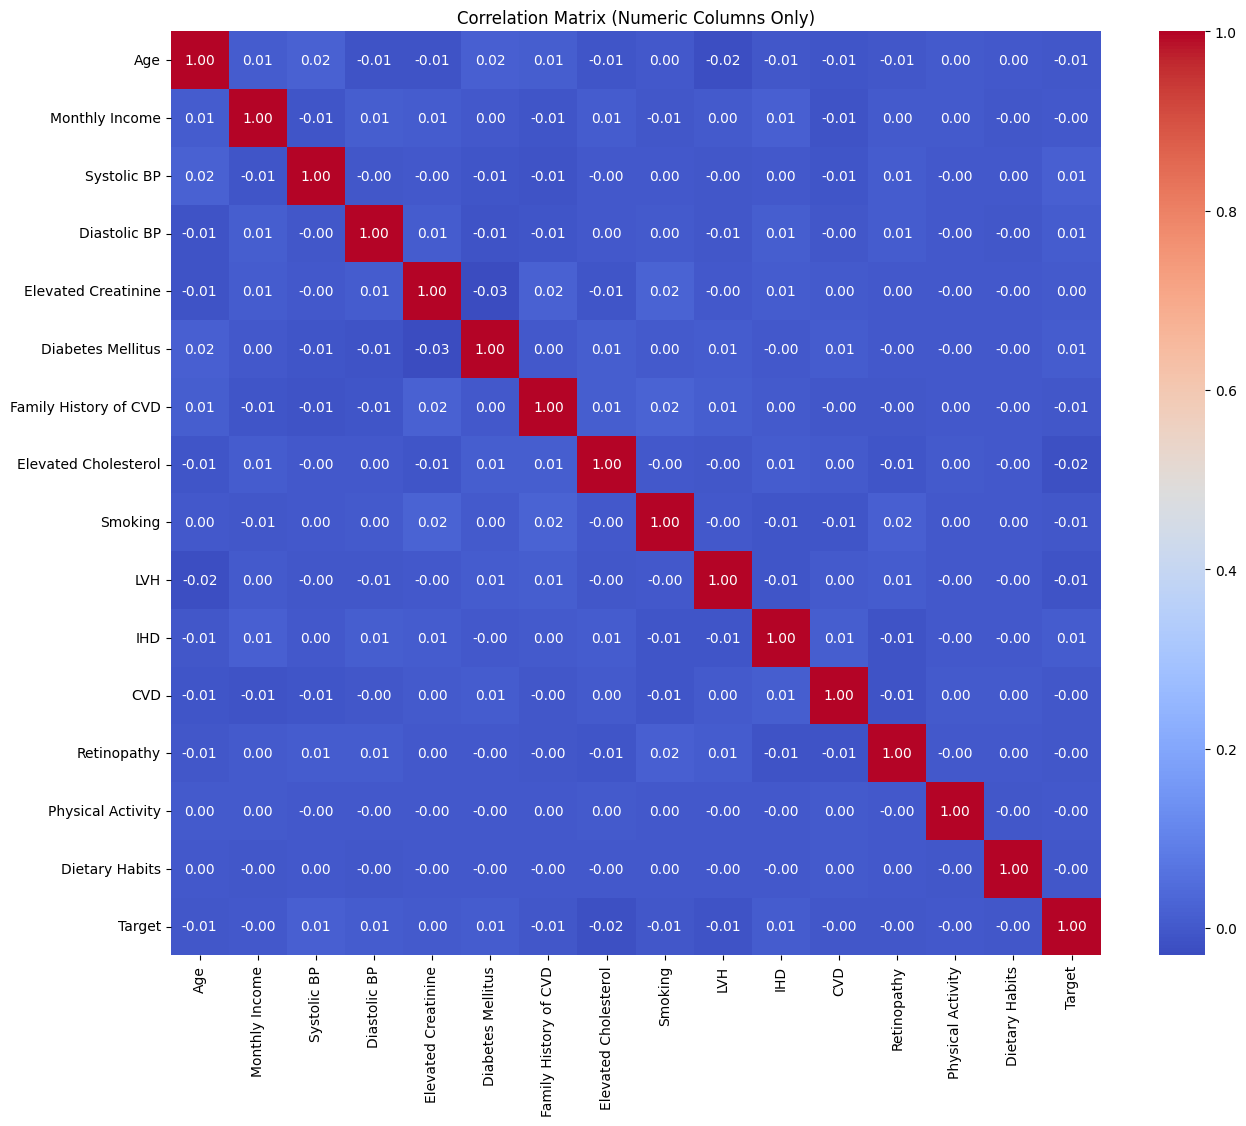

Correlation with target:
Target                   1.000000
Systolic BP              0.013879
IHD                      0.009199
Diabetes Mellitus        0.008144
Diastolic BP             0.006021
Elevated Creatinine      0.003980
Monthly Income          -0.000711
Physical Activity       -0.001634
Dietary Habits          -0.002844
Retinopathy             -0.004425
CVD                     -0.004470
Smoking                 -0.005109
Age                     -0.005134
Family History of CVD   -0.005946
LVH                     -0.012366
Elevated Cholesterol    -0.019350
Name: Target, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Only numeric columns for correlation
numeric_cols = X.select_dtypes(include='number').columns.tolist()
numeric_df = X[numeric_cols].copy()
numeric_df['Target'] = y

# Correlation matrix
corr = numeric_df.corr()

# Heatmap
plt.figure(figsize=(15,12))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix (Numeric Columns Only)")
plt.show()

# Correlation with target
print("Correlation with target:")
print(corr['Target'].sort_values(ascending=False))

## Split Data for Modeling

Split the preprocessed features (X) and target variable (y) into training and testing sets to prepare for machine learning model development. This ensures the model is evaluated on unseen data.

--> Train/Validation/Test Split (70/10/20)

In [ ]:
from sklearn.model_selection import train_test_split

# Split: train+val (80%) vs test (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Split train+val: train (70%), val (10%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.125, random_state=42, stratify=y_train_val
)

print(f"Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")

Train: (70000, 35), Validation: (10000, 35), Test: (20000, 35)


#Training Classification Models

##1. Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Validation
y_val_pred = rf.predict(X_val)
print("Random Forest Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

# Test
y_test_pred = rf.predict(X_test)
print("Random Forest Test Accuracy:", accuracy_score(y_test, y_test_pred))

Random Forest Validation Accuracy: 0.9535
              precision    recall  f1-score   support

           0       0.97      0.86      0.91      2767
           1       0.95      0.99      0.97      7233

    accuracy                           0.95     10000
   macro avg       0.96      0.92      0.94     10000
weighted avg       0.95      0.95      0.95     10000

Random Forest Test Accuracy: 0.9521


##2. XGBoost Classifier

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train, y_train)

# Validation
y_val_pred = xgb.predict(X_val)
print("XGBoost Validation Accuracy:", accuracy_score(y_val, y_val_pred))

# Test
y_test_pred = xgb.predict(X_test)
print("XGBoost Test Accuracy:", accuracy_score(y_test, y_test_pred))

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:04:07] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Validation Accuracy: 0.7795
XGBoost Test Accuracy: 0.78


## 3. LightGBM Classifier

In [ ]:
from lightgbm import LGBMClassifier

lgb = LGBMClassifier(random_state=42)
lgb.fit(X_train, y_train)

# Validation
y_val_pred = lgb.predict(X_val)
print("LightGBM Validation Accuracy:", accuracy_score(y_val, y_val_pred))

# Test
y_test_pred = lgb.predict(X_test)
print("LightGBM Test Accuracy:", accuracy_score(y_test, y_test_pred))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 50631, number of negative: 19369
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018411 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 315
[LightGBM] [Info] Number of data points in the train set: 70000, number of used features: 35
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.723300 -> initscore=0.960890
[LightGBM] [Info] Start training from score 0.960890
LightGBM Validation Accuracy: 0.7408
LightGBM Test Accuracy: 0.7397


## 4. CatBoost Classifier

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train, y_train)

# Validation
y_val_pred = cat.predict(X_val)
print("CatBoost Validation Accuracy:", accuracy_score(y_val, y_val_pred))

# Test
y_test_pred = cat.predict(X_test)
print("CatBoost Test Accuracy:", accuracy_score(y_test, y_test_pred))

CatBoost Validation Accuracy: 0.7968
CatBoost Test Accuracy: 0.79335


#Training Scaling Models

##1. SVC

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Scale features
scaler_svc = StandardScaler()
X_train_svc = scaler_svc.fit_transform(X_train)
X_val_svc = scaler_svc.transform(X_val)
X_test_svc = scaler_svc.transform(X_test)

# Train SVC
svc = SVC(probability=True, random_state=42)
svc.fit(X_train_svc, y_train)

# Validation
y_val_pred = svc.predict(X_val_svc)
print("SVC Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

# Test
y_test_pred = svc.predict(X_test_svc)
print("SVC Test Accuracy:", accuracy_score(y_test, y_test_pred))

SVC Validation Accuracy: 0.7876
              precision    recall  f1-score   support

           0       0.95      0.25      0.39      2767
           1       0.78      0.99      0.87      7233

    accuracy                           0.79     10000
   macro avg       0.86      0.62      0.63     10000
weighted avg       0.82      0.79      0.74     10000

SVC Test Accuracy: 0.7887


##2. MLP

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# Scale features for MLP
scaler_mlp = StandardScaler()
X_train_mlp = scaler_mlp.fit_transform(X_train)
X_val_mlp = scaler_mlp.transform(X_val)
X_test_mlp = scaler_mlp.transform(X_test)

# Train MLP
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp.fit(X_train_mlp, y_train)

# Validation
y_val_pred = mlp.predict(X_val_mlp)
print("MLP Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

# Test
y_test_pred = mlp.predict(X_test_mlp)
print("MLP Test Accuracy:", accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))

MLP Validation Accuracy: 0.8448
              precision    recall  f1-score   support

           0       0.78      0.61      0.68      2767
           1       0.86      0.94      0.90      7233

    accuracy                           0.84     10000
   macro avg       0.82      0.77      0.79     10000
weighted avg       0.84      0.84      0.84     10000

MLP Test Accuracy: 0.8516
              precision    recall  f1-score   support

           0       0.80      0.61      0.70      5534
           1       0.86      0.94      0.90     14466

    accuracy                           0.85     20000
   macro avg       0.83      0.78      0.80     20000
weighted avg       0.85      0.85      0.84     20000



/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


#Model Evaluation

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Function to evaluate model and split confusion matrix
def evaluate_model_detailed(model, X_val, y_val, X_test, y_test, model_name):
    # Predictions
    y_val_pred = model.predict(X_val)
    y_test_pred = model.predict(X_test)

    # Validation confusion matrix
    tn_val, fp_val, fn_val, tp_val = confusion_matrix(y_val, y_val_pred).ravel()

    # Test confusion matrix
    tn_test, fp_test, fn_test, tp_test = confusion_matrix(y_test, y_test_pred).ravel()

    # Metrics dictionary
    metrics = {
        "Model": model_name,
        "Val Accuracy": accuracy_score(y_val, y_val_pred),
        "Val Precision": precision_score(y_val, y_val_pred),
        "Val Recall": recall_score(y_val, y_val_pred),
        "Val F1": f1_score(y_val, y_val_pred),
        "Val TP": tp_val,
        "Val FP": fp_val,
        "Val TN": tn_val,
        "Val FN": fn_val,
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Test Precision": precision_score(y_test, y_test_pred),
        "Test Recall": recall_score(y_test, y_test_pred),
        "Test F1": f1_score(y_test, y_test_pred),
        "Test TP": tp_test,
        "Test FP": fp_test,
        "Test TN": tn_test,
        "Test FN": fn_test
    }

    return metrics

# Evaluate all models
all_metrics_detailed = []
all_metrics_detailed.append(evaluate_model_detailed(rf, X_val, y_val, X_test, y_test, "Random Forest"))
all_metrics_detailed.append(evaluate_model_detailed(xgb, X_val, y_val, X_test, y_test, "XGBoost"))
all_metrics_detailed.append(evaluate_model_detailed(lgb, X_val, y_val, X_test, y_test, "LightGBM"))
all_metrics_detailed.append(evaluate_model_detailed(cat, X_val, y_val, X_test, y_test, "CatBoost"))
all_metrics_detailed.append(evaluate_model_detailed(svc, X_val_svc, y_val, X_test_svc, y_test, "SVC"))
all_metrics_detailed.append(evaluate_model_detailed(mlp, X_val_mlp, y_val, X_test_mlp, y_test, "MLP"))

# Create comparison table
comparison_df = pd.DataFrame(all_metrics_detailed)

# Show full table
pd.set_option('display.max_columns', None)
comparison_df

,Model,Val Accuracy,Val Precision,Val Recall,Val F1,Val TP,Val FP,Val TN,Val FN,Test Accuracy,Test Precision,Test Recall,Test F1,Test TP,Test FP,Test TN,Test FN
0,Random Forest,0.9535,0.947975,0.990046,0.968553,7161,393,2374,72,0.95210,0.945280,0.991152,0.967672,14338,830,4704,128
1,XGBoost,0.7795,0.771490,0.987695,0.866307,7144,2116,651,89,0.78000,0.772113,0.987211,0.866513,14281,4215,1319,185
2,LightGBM,0.7408,0.736520,0.999032,0.847923,7226,2585,182,7,0.73970,0.735647,0.999170,0.847394,14454,5194,340,12
3,CatBoost,0.7968,0.782387,0.996129,0.876414,7205,2004,763,28,0.79335,0.780559,0.993640,0.874304,14374,4041,1493,92
4,SVC,0.7876,0.775299,0.994608,0.871366,7194,2085,682,39,0.78870,0.775654,0.995921,0.872094,14407,4167,1367,59
5,MLP,0.8448,0.861249,0.936264,0.897191,6772,1091,1676,461,0.85160,0.864738,0.942209,0.901813,13630,2132,3402,836


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=comparison_df)

https://docs.google.com/spreadsheets/d/1Kl0ARnj_dByzK2um9A0cWICHRd9DfZ5bGRAyMFa9QQ8/edit#gid=0


#Ensemble Section

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

##SVC pipleine

In [ ]:
svc_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(probability=True, random_state=42))
])

##Hybrid Models

##Model A: Tree Ensemble

In [ ]:
ensemble_tree = VotingClassifier(
    estimators=[
        ('rf', rf),
        ('xgb', xgb),
        ('cat', cat)
    ],
    voting='soft'
)

ensemble_tree.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [16:46:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_...
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('cat',
                              CatBoostClassifier(random_state=42, verbose=0))],
                 voting='soft')

##Model B: Mixed Ensemble (with SVC ⭐)

In [ ]:
ensemble_mixed = VotingClassifier(
    estimators=[
        ('rf', rf),
        ('cat', cat),
        ('svc', svc_pipe)
    ],
    voting='soft'
)

ensemble_mixed.fit(X_train, y_train)

VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=42)),
                             ('cat',
                              CatBoostClassifier(random_state=42, verbose=0)),
                             ('svc',
                              Pipeline(steps=[('scaler', StandardScaler()),
                                              ('svc',
                                               SVC(probability=True,
                                                   random_state=42))]))],
                 voting='soft')

##Model C: Lightweight Ensemble

In [ ]:
ensemble_light = VotingClassifier(
    estimators=[
        ('rf', rf),
        ('lgb', lgb)
    ],
    voting='soft'
)

ensemble_light.fit(X_train, y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 50631, number of negative: 19369
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.022436 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 315
[LightGBM] [Info] Number of data points in the train set: 70000, number of used features: 35
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.723300 -> initscore=0.960890
[LightGBM] [Info] Start training from score 0.960890


VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=42)),
                             ('lgb', LGBMClassifier(random_state=42))],
                 voting='soft')

##Evaluation Fucntion

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def get_metrics(model, X_val, y_val, X_test, y_test, name):

    # Predictions
    y_val_pred = model.predict(X_val)
    y_test_pred = model.predict(X_test)

    # Confusion Matrix (Validation)
    tn_v, fp_v, fn_v, tp_v = confusion_matrix(y_val, y_val_pred).ravel()

    # Confusion Matrix (Test)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, y_test_pred).ravel()

    return {
        "Model": name,

        # Validation metrics
        "Val Accuracy": accuracy_score(y_val, y_val_pred),
        "Val Precision": precision_score(y_val, y_val_pred),
        "Val Recall": recall_score(y_val, y_val_pred),
        "Val F1": f1_score(y_val, y_val_pred),

        "Val TP": tp_v,
        "Val FP": fp_v,
        "Val TN": tn_v,
        "Val FN": fn_v,

        # Test metrics
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Test Precision": precision_score(y_test, y_test_pred),
        "Test Recall": recall_score(y_test, y_test_pred),
        "Test F1": f1_score(y_test, y_test_pred),

        "Test TP": tp_t,
        "Test FP": fp_t,
        "Test TN": tn_t,
        "Test FN": fn_t
    }

#Comparison of Ensemble models

In [ ]:
results = []

results.append(get_metrics(ensemble_tree, X_val, y_val, X_test, y_test, "Ensemble - Tree"))
results.append(get_metrics(ensemble_mixed, X_val, y_val, X_test, y_test, "Ensemble - Mixed (SVC)"))
results.append(get_metrics(ensemble_light, X_val, y_val, X_test, y_test, "Ensemble - Light"))

df_ensemble = pd.DataFrame(results)
df_ensemble

,Model,Val Accuracy,Val Precision,Val Recall,Val F1,Val TP,Val FP,Val TN,Val FN,Test Accuracy,Test Precision,Test Recall,Test F1,Test TP,Test FP,Test TN,Test FN
0,Ensemble - Tree,0.8489,0.827570,0.999309,0.905367,7228,1506,1261,5,0.84685,0.826042,0.998548,0.904140,14445,3042,2492,21
1,Ensemble - Mixed (SVC),0.8657,0.847288,0.993364,0.914529,7185,1295,1472,48,0.86440,0.845828,0.993640,0.913795,14374,2620,2914,92
2,Ensemble - Light,0.8756,0.853584,0.999447,0.920774,7229,1240,1527,4,0.87250,0.850677,0.999101,0.918934,14453,2537,2997,13


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df_ensemble)

https://docs.google.com/spreadsheets/d/1e2kFUi0iVJyJ08fMJ9EqzixT-28NmlLPdRD0RYWsWAQ/edit#gid=0


#Feature Importance

In [ ]:
import pandas as pd

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_importance
rf_importance.head(10)

,Feature,Importance
2,Systolic BP,0.170054
0,Age,0.167857
3,Diastolic BP,0.156405
1,Monthly Income,0.047463
6,Family History of CVD,0.026511
10,IHD,0.023290
8,Smoking,0.023283
4,Elevated Creatinine,0.022079
22,Education_Primary,0.020666
14,Dietary Habits,0.018779


In [ ]:
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
}).sort_values(by="Importance", ascending=False)

xgb_importance
xgb_importance.head(10)

,Feature,Importance
18,Education_Higher Secondary,0.039398
9,LVH,0.037990
19,Education_Madrasa,0.036554
12,Retinopathy,0.034970
7,Elevated Cholesterol,0.034633
6,Family History of CVD,0.034534
21,Education_Post-Graduate,0.034256
8,Smoking,0.034255
5,Diabetes Mellitus,0.034010
15,Sex_Female,0.033709


In [ ]:
lgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgb.feature_importances_
}).sort_values(by="Importance", ascending=False)

lgb_importance
lgb_importance.head(10)

,Feature,Importance
2,Systolic BP,449
0,Age,389
3,Diastolic BP,312
1,Monthly Income,190
15,Sex_Female,123
6,Family History of CVD,105
8,Smoking,94
22,Education_Primary,81
23,Education_Secondary,75
24,Occupation_Agriculture,72


In [ ]:
top_features = pd.DataFrame({
    "Random Forest": rf_importance.head(10)["Feature"].values,
    "XGBoost": xgb_importance.head(10)["Feature"].values,
    "LightGBM": lgb_importance.head(10)["Feature"].values
})

top_features

,Random Forest,XGBoost,LightGBM
0,Systolic BP,Education_Higher Secondary,Systolic BP
1,Age,LVH,Age
2,Diastolic BP,Education_Madrasa,Diastolic BP
3,Monthly Income,Retinopathy,Monthly Income
4,Family History of CVD,Elevated Cholesterol,Sex_Female
5,IHD,Family History of CVD,Family History of CVD
6,Smoking,Education_Post-Graduate,Smoking
7,Elevated Creatinine,Smoking,Education_Primary
8,Education_Primary,Diabetes Mellitus,Education_Secondary
9,Dietary Habits,Sex_Female,Occupation_Agriculture


In [ ]:
import joblib

joblib.dump(rf, "rf_model.pkl")

['rf_model.pkl']

In [ ]:
from google.colab import files
files.download("rf_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>